## Recap: Last Class — CNN Under the Hood

Last class we built a small CNN **completely from scratch** (forward *and* backward passes, every gradient coded by hand) to classify MNIST digits 0 vs 1. We saw what a convolution, ReLU, max-pooling, reshape and dense layer do mathematically, and how gradients flow backwards through them (and we verified our gradients against autograd).

**Why this matters today:** we now trust what `nn.Conv2d`, `nn.MaxPool2d`, `nn.Linear` and autograd do under the hood, so from here on we use PyTorch's built-in layers and pretrained models.

#### **Agenda:**
In this Lecture, we will learn about :
   - Recognition of world famous landmark
   - Standard CNN architecture like AlexNet and VGGNet
   - Transfer learning using VGGNet


###Problem Statement:

- Suppose you are working as a Data Scientist at a photo-mapping startup. You have been given a task to automate the categorization of famous landmarks.

<center><img src='https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/249/207/original/1.png?1793084542' ></center>

- The dataset is obtained by downloading images of 10 famous landmarks from the web.
- Using these images, you have to train a CNN model
- For inference, the CNN model will be fed with an image (similar to how a visual-search app works) and it will output the most probable landmark category

### What is visual / reverse image search?

If you're not familiar with the idea, it's a tool that lets you search using an image instead of text, and returns visually similar results or identifies what's in the photo.

## Class Plan (120 minutes)

| # | Block | Time | Cumulative |
|---|-------|------|-----------|
| 1 | Problem, setup, data loading and exploration | 12 min | 0–12 |
| 2 | Why not from scratch? ImageNet, AlexNet, top-k accuracy, Quiz 2–3 | 15 min | 12–27 |
| 3 | VGGNet: small filters, depth, Quiz 4 | 13 min | 27–40 |
| 4 | Build VGG16 from scratch and train it (and see why it struggles) | 17 min | 40–57 |
| 5 | **Break** | 5 min | 57–62 |
| 6 | Transfer learning: the idea, feature extraction vs fine-tuning | 10 min | 62–72 |
| 7 | Transfer learning with VGG16: build, freeze, train, evaluate, predictions, Quiz 5 | 22 min | 72–94 |
| 8 | VGG shortcomings, Global Average Pooling, Quiz 6, conclusion | 10 min | 94–104 |
| – | Buffer / optional fine-tuning demo / exercises | 16 min | 104–120 |

### What should be the performance metric?

**Accuracy** = number of correct predictions / total number of samples. Because the test set here is tiny (a few dozen images), each test image moves the accuracy by about 2 points, so treat small differences with caution. We will also use **top-k accuracy** later.

> **🤖 AI Infusion #1 (2 min, optional):** ask an AI assistant: *"In plain language and with a simple analogy, why can reusing a model trained on ImageNet help me classify a completely different set of images, such as landmarks, with very little data?"* Compare its answer with what we cover today.

### Importing python packages

In [ ]:
import os
import glob
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

import warnings
warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 12})

SEED = 111
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


### Downloading the dataset

In [ ]:
!gdown 11LQILlalZGi_skLIipnpTyh-At77B_j6

Downloading...
From (original): https://drive.google.com/uc?id=11LQILlalZGi_skLIipnpTyh-At77B_j6
From (redirected): https://drive.google.com/uc?id=11LQILlalZGi_skLIipnpTyh-At77B_j6&confirm=t&uuid=a1e419df-83ff-4808-ba70-50edfe8fd303
To: /content/New_landmark_images.zip
100% 112M/112M [00:02<00:00, 47.1MB/s]


In [ ]:
!unzip -q New_landmark_images.zip

#### Exploring the data first

The folders are `New_landmark_images/{train,validation,test}/<class_name>/`. Let's count the images per class and split.

                        train  validation  test
01.Niagara_Falls           66          16     5
02.Golden_Gate_Bridge      70          16     5
03.Kantanagar_Temple       88          16     5
04.Eiffel_Tower            64          15     4
05.Washington_Monument     83          16     4
06.Hanging_Temple          70          15     4
07.Forth_Bridge            82          15     4
08.Gateway_of_India        87          15     4
09.Machu_Picchu            55          16     4
10.Great_Wall_of_China     72          15     4

Totals: {'train': 737, 'validation': 155, 'test': 43}


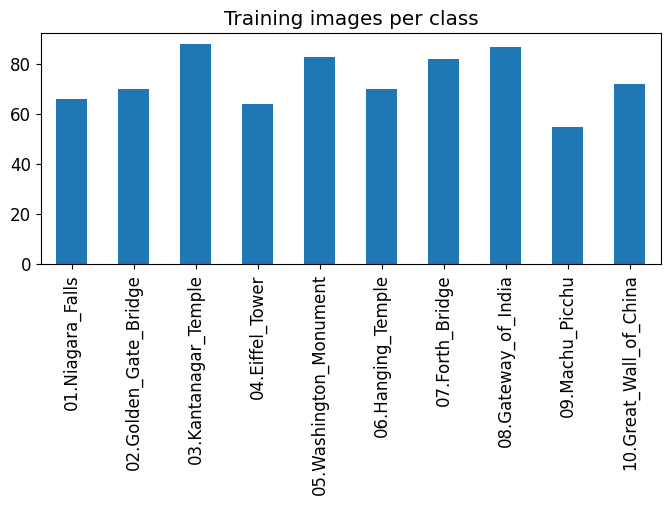

In [ ]:
ROOT = "New_landmark_images"
class_names = sorted(d for d in os.listdir(f"{ROOT}/train") if os.path.isdir(f"{ROOT}/train/{d}"))

counts = pd.DataFrame({
    split: {c: len(os.listdir(f"{ROOT}/{split}/{c}")) for c in class_names}
    for split in ["train", "validation", "test"]
})
print(counts)
print("\nTotals:", counts.sum().to_dict())
counts["train"].plot.bar(title="Training images per class", figsize=(8, 3))
plt.show()

- The classes are (roughly) **balanced**, and there are only a few dozen images per class in train, even fewer in validation and just a handful per class in test. This is a **small dataset**, the typical situation where transfer learning shines.

Let's look at one random image per class (note that images come in different sizes):

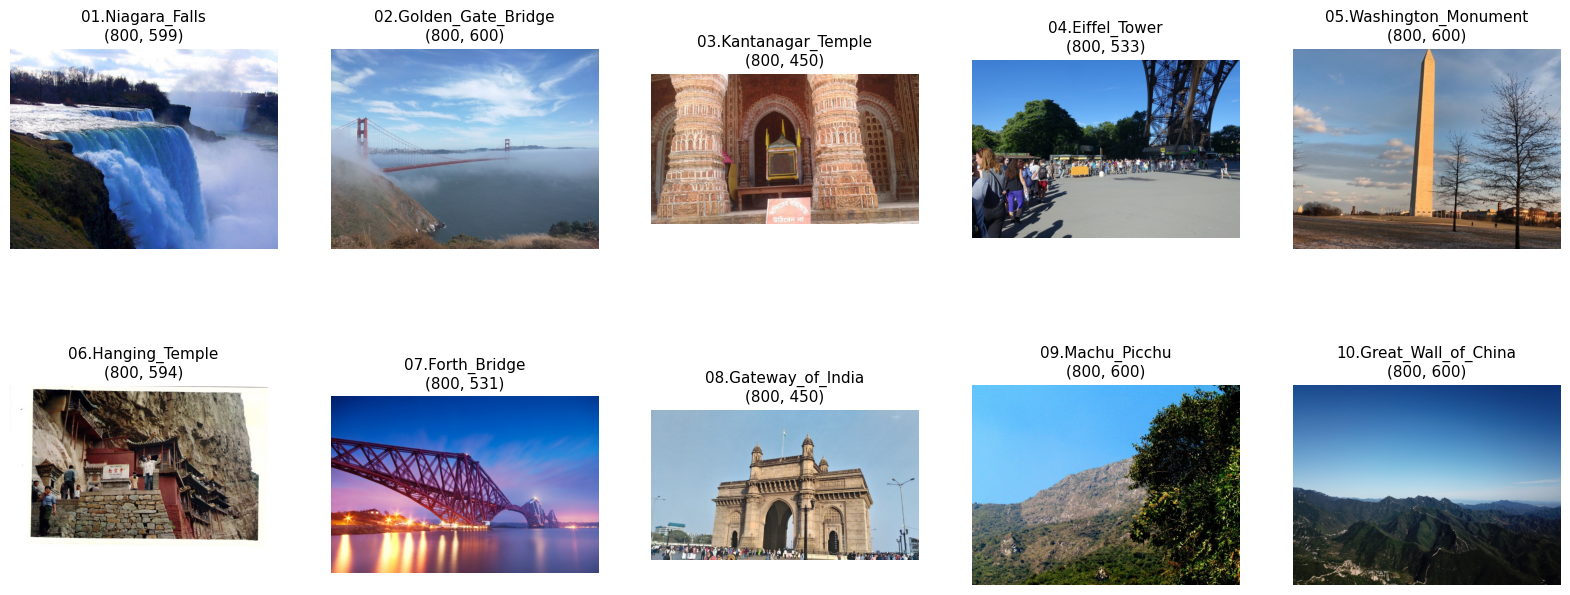

In [ ]:
plt.figure(figsize=(20, 8))
for i, cls in enumerate(class_names):
    path = random.choice(glob.glob(f"{ROOT}/train/{cls}/*"))
    img = Image.open(path)
    plt.subplot(2, 5, i + 1)
    plt.imshow(img); plt.title(f"{cls}\n{img.size}", fontsize=11); plt.axis("off")
plt.show()

#### What preprocessing is needed?

1. **Resize** all images to the same size, **224×224** (what VGG expects).
2. **Rescale** pixels from 0–255 to 0–1 (`ToTensor`).
3. **Standardize with the ImageNet mean and standard deviation.** The pretrained network was trained on images normalized this way; feeding it differently scaled inputs would hurt its pretrained features. We use the same normalization everywhere (also for the model trained from scratch) to keep the comparison fair.

#### **Quiz-1**
Why do we normalize the inputs?

> (a) It makes the cost function faster to optimize

> (b) It makes the parameter initialization faster

> (c) It makes it easier to visualize the data

> (d) Normalization is another word for regularization — it helps to reduce variance

**Ans: (a)** Inputs on a similar scale give a better-conditioned loss surface, so gradient descent converges faster. (For a *pretrained* network there is a second reason: it expects the same normalization it was trained with.)

In [ ]:
IMG_SIZE = (224, 224)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
BATCH_SIZE = 32

preprocess = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),                                   # PIL (H,W,C) 0..255  ->  tensor (C,H,W) 0..1
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),       # (x - mean) / std per channel
])

train_dataset = datasets.ImageFolder(f"{ROOT}/train", transform=preprocess)
val_dataset   = datasets.ImageFolder(f"{ROOT}/validation", transform=preprocess)
test_dataset  = datasets.ImageFolder(f"{ROOT}/test", transform=preprocess)

train_ds = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_ds   = DataLoader(val_dataset, batch_size=BATCH_SIZE)
test_ds  = DataLoader(test_dataset, batch_size=BATCH_SIZE)

print("Classes:", train_dataset.classes)
images, labels = next(iter(train_ds))
print("One batch:", images.shape)

Classes: ['01.Niagara_Falls', '02.Golden_Gate_Bridge', '03.Kantanagar_Temple', '04.Eiffel_Tower', '05.Washington_Monument', '06.Hanging_Temple', '07.Forth_Bridge', '08.Gateway_of_India', '09.Machu_Picchu', '10.Great_Wall_of_China']
One batch: torch.Size([32, 3, 224, 224])


## How can we classify these landmarks?

1. **Create a CNN from scratch.** But then we must decide: how many conv layers? Which architecture? 3×3 or 5×5 or 11×11 kernels? How to combine conv, pooling and FC layers? And can we get high accuracy from such a small dataset? This needs a lot of experimentation and training time.
2. **Reuse a state-of-the-art model trained on a huge dataset (transfer learning).** We will compare both approaches using **VGGNet**.

Before VGG, let's understand its predecessor, **AlexNet**.

### What is AlexNet?

- AlexNet won the **ImageNet competition (ILSVRC) in 2012** with a CNN, by a large margin: about **84.7% top-5 accuracy versus about 74%** for the runner-up. It is widely seen as the start of the deep-learning revolution in vision.
- CNNs themselves were much older (LeCun et al., 1989). What was missing before was **compute (GPUs) and large labelled datasets**.

**What is ImageNet / ILSVRC?** ImageNet is a database of over 14 million labelled images (over 21,000 categories) organized in a hierarchy. The ILSVRC competition uses a 1000-class subset and became the benchmark for vision models.

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/046/617/original/Screenshot_2023-09-06_at_11.34.09_AM.png?1693980427 width=800>

####What is top-k accuracy ?

- In many multiclass classification problems in Computer Vision, Topk (like top3, top 5) accuracy is a better measure of model performance.
- Example, in a recommender system it makes more sense to show the top 3 or 5 recommended products to a customer rather than just the single top-most-recommended product.

- In top-k accuracy, we get a point if the right answer appears in the top k guesses.
<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/046/615/original/Screenshot_2023-09-06_at_11.34.15_AM.png?1693980284 width=800>

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/046/616/original/Screenshot_2023-09-06_at_11.34.20_AM.png?1693980334 width=800>

How is top-k accuracy helpful when working with images?
- Some classes differ only slightly (a pickup truck vs a minivan), and even human labels are not 100% correct.
- Showing/checking the top 3 or 5 guesses is often more meaningful (like a recommender system showing several items), so apart from accuracy we also report **top-k accuracy**.

####  **What was so new about AlexNet?**
 1) **Graphics processing units (GPUs)**
- This was one of the first times someone **successfully trained a large CNN using GPUs**
- **GPUs have a large number of cores** (in the thousands) which allow **parallel computing**
- So we can parallelize our model's computation across many threads


2) **Rectified linear unit (ReLU) activation**
- Before this (2012), tanh and sigmoid were the commonly used activation functions
- How did ReLU improve performance?
 - **Better gradient propagation**: fewer vanishing-gradient problems compared to tanh
 - **Efficient computation**: ReLU is cheap compared to tanh and sigmoid, which require an expensive exponential operation



3) **Regularization**
- With regularization they were able to reduce overfitting
- They used **Dropout** and **Data Augmentation**: random 224x224 crops from 256x256 images, horizontal flips and colour (PCA) jitter



4) **Pooling layers**
- With pooling, we can reduce the dimensions of feature maps
- Thus, it reduces the number of parameters to learn, making the model faster to train


5) **Depth**
- Increasing the depth helped improve the learning capacity of the model


Now let's see the architecture of AlexNet

#### **Quiz-2**
An input image of shape (227, 227, 3) is convolved with an (11, 11) kernel using 96 filters (stride 1, no padding), giving an output of shape (217, 217, 96). What is the total number of parameters?

> (a) (11 * 11 * 3 + 1) * 96

> (b) 11 * 11 * 3 * 96

> (c) 96

> (d) None of the above

**Ans: (a)**. Weights = 11 × 11 × 3 × 96 = 34,848 and biases = 96, so the total is 34,944. Note that the number of parameters does *not* depend on the image size. (The real AlexNet uses stride 4 in this layer, giving 55×55×96.)

<center> <img src="https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/249/208/original/2.png?1793084576"></center>
  <caption><center> <font color='yellow'> Figure <font color='yellow'>  : AlexNet Architecture<br>  </center></caption>


<center><img src='https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/249/211/original/3.png?1793084597' ></center>
<caption><center> <font color='yellow'> Figure <font color='yellow'>  : AlexNet layers Computation<br>  </center></caption>

  

- AlexNet has 5 CONV layers and 3 FC layers and about **61 million parameters**.
- Single-crop ImageNet accuracy of the pretrained weights in `torchvision` is in the table at the end of this notebook (with VGG for comparison).

#### **Quiz-3**

Which of the following options can be used to reduce overfitting in deep learning models?

1. Increase architectural complexity
2. Use data augmentation
3. Using dropouts
4. Add regularization

> (a) 1,2,3  > (b) 2,3,4  > (c) 1,3,4  > (d) All of these

**Ans: (b) 2,3,4.** Increasing model complexity adds capacity and tends to make overfitting *worse*.

#### **What are the shortcomings of AlexNet?**

- It uses **large filters (11×11, 5×5)**, which have many parameters and are expensive.
- It is relatively shallow. Deeper networks have more **expressive power** (several successive non-linearities), a larger **receptive field** built cheaply from small filters (e.g. 3×3 layers interleaved with pooling can "see" a 128×128 region without needing a 128×128 filter), and learn a **hierarchy** of features (edges → textures → parts → objects) instead of memorizing in one wide layer.

**Can we get the same effect with smaller filters?** Yes: use 3×3 filters, stacked. Let's count parameters (per input/output channel pair, ignoring biases):

| Option | Receptive field | Weights |
|---|---|---|
| one 5×5 filter | 5×5 | 25 |
| two stacked 3×3 filters | 5×5 | 2 × 9 = **18** |
| one 7×7 filter | 7×7 | 49 |
| three stacked 3×3 filters | 7×7 | 3 × 9 = **27** |

Stacking gives the same receptive field with fewer parameters, plus **extra non-linearities** (a ReLU after each conv).

In [ ]:
# Verify with real layers: C = 64 input and output channels, biases ignored
C = 64
one_5x5   = nn.Conv2d(C, C, 5, bias=False)
two_3x3   = nn.Sequential(nn.Conv2d(C, C, 3, bias=False), nn.Conv2d(C, C, 3, bias=False))
count = lambda m: sum(p.numel() for p in m.parameters())
print("one 5x5  :", count(one_5x5))
print("two 3x3  :", count(two_3x3), f"({100 * count(two_3x3) / count(one_5x5):.0f}% of the 5x5 filter)")

one 5x5  : 102400
two 3x3  : 73728 (72% of the 5x5 filter)


### VGGNet

- VGG (Oxford's Visual Geometry Group) was the **runner-up in the classification task and winner of the localization task at ILSVRC 2014**.
- Architecture: very similar in spirit to AlexNet but **much deeper and uniform**: only **3×3 convolutions** and 2×2 max-pooling, grouped in 5 blocks, followed by FC layers.
- **VGG16** = 16 weight layers (13 conv + 3 FC); **VGG19** = 19 weight layers (16 conv + 3 FC).

<center> <img src="https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/249/213/original/4.png?1793084629"></center>
  <caption><center> <font color='yellow'> Figure <font color='yellow'>  : VGG16 Architecture<br>  </center></caption>

<center> <img src="https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/249/215/original/5.png?1793084651"></center>
  <caption><center> <font color='yellow'> Figure: <font color='yellow'>  VGG16 layers Computation<br>  </center></caption>

#### **Quiz-4**

Increasing the **number** of convolutional layers will necessarily increase the performance of a convolutional neural network.

> (a) TRUE  > (b) FALSE

**Ans: (b) FALSE.** More conv layers do not automatically help. Past a certain depth, plain stacked networks become hard to optimize (vanishing/exploding gradients, and the "degradation problem": deeper plain networks can even get *higher training error*). This motivated architectures such as ResNet with skip connections. Depth helps only when paired with good initialization, normalization or skip connections.

## Building VGG16 from scratch

Every VGG block is: *n* × (3×3 Conv + ReLU) followed by a 2×2 max-pool (which halves the height and width). VGG16 uses (2, 2, 3, 3, 3) convolutions in its five blocks; **VGG19** would use (2, 2, 4, 4, 4). So we write a small helper that builds one block.

> To keep training fast we replace the three big FC layers (25088→4096→4096→1000) by a single `Linear(512·7·7, 10)` layer.

In [ ]:
def vgg_block(in_ch, out_ch, n_convs):
    layers = []
    for i in range(n_convs):
        layers += [nn.Conv2d(in_ch if i == 0 else out_ch, out_ch, kernel_size=3, padding=1),
                   nn.ReLU(inplace=True)]
    layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
    return nn.Sequential(*layers)

Now stack five blocks (channels 64 → 128 → 256 → 512 → 512) and add the classifier:

In [ ]:
class VGGScratch(nn.Module):
    def __init__(self, convs_per_block=(2, 2, 3, 3, 3), num_classes=10):   # (2,2,3,3,3) = VGG16, (2,2,4,4,4) = VGG19
        super().__init__()
        channels = [64, 128, 256, 512, 512]
        blocks, in_ch = [], 3
        for n_convs, out_ch in zip(convs_per_block, channels):
            blocks.append(vgg_block(in_ch, out_ch, n_convs))
            in_ch = out_ch
        self.features = nn.Sequential(*blocks)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(512 * 7 * 7, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

Let's watch the shape shrink as an image goes through the five blocks (224 → 112 → 56 → 28 → 14 → 7), and count the parameters:

In [ ]:
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total params: {total:,} | Trainable params: {trainable:,}")

scratch_model = VGGScratch().to(device)

x = torch.zeros(1, 3, 224, 224).to(device)
for i, block in enumerate(scratch_model.features):
    x = block(x)
    print(f"after block {i + 1}: {tuple(x.shape)}")
count_params(scratch_model)

after block 1: (1, 64, 112, 112)
after block 2: (1, 128, 56, 56)
after block 3: (1, 256, 28, 28)
after block 4: (1, 512, 14, 14)
after block 5: (1, 512, 7, 7)
Total params: 14,965,578 | Trainable params: 14,965,578


### Training code, piece by piece

**Piece 1 — one training epoch** (forward → loss → backward → update; we track loss and accuracy):

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += images.size(0)
    return total_loss / total, correct / total

**Piece 2 — evaluation** (no gradients, `model.eval()`). We also return top-k accuracy, because we introduced it above:

In [ ]:
@torch.no_grad()
def evaluate(model, loader, criterion=None, topk=(1, 3)):
    model.eval()
    criterion = criterion or nn.CrossEntropyLoss()
    total_loss, total = 0.0, 0
    correct = {k: 0 for k in topk}
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        total_loss += criterion(outputs, labels).item() * images.size(0)
        top_preds = outputs.topk(max(topk), dim=1).indices                  # (batch, max_k) best guesses
        for k in topk:
            correct[k] += (top_preds[:, :k] == labels[:, None]).any(dim=1).sum().item()
        total += images.size(0)
    return total_loss / total, {k: correct[k] / total for k in topk}

**Piece 3 — the `fit` loop and the plotting helper:**

In [ ]:
def fit(model, train_loader, val_loader, optimizer, epochs=5):
    criterion = nn.CrossEntropyLoss()
    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_topk = evaluate(model, val_loader, criterion, topk=(1,))
        va_acc = va_topk[1]
        for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[k].append(v)
        print(f"Epoch {epoch}/{epochs} - loss: {tr_loss:.4f} - acc: {tr_acc:.4f} - val_loss: {va_loss:.4f} - val_acc: {va_acc:.4f}")
    return history

def plot_history(history, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for a, metric in zip(ax, ["loss", "accuracy"]):
        a.plot(history[metric], "--", label="train"); a.plot(history["val_" + metric], label="val")
        a.set_xlabel("epoch"); a.set_ylabel(metric); a.set_title(f"{metric} {title}"); a.legend()
    plt.show()

### Train VGG16 from scratch

We use SGD with momentum 0.9 and learning rate 0.01 (the recipe of the original VGG paper).

In [ ]:
torch.manual_seed(10)
scratch_model = VGGScratch().to(device)
optimizer = optim.SGD(scratch_model.parameters(), lr=0.01, momentum=0.9)
history_scratch = fit(scratch_model, train_ds, val_ds, optimizer, epochs=5)

Epoch 1/5 - loss: 2.3016 - acc: 0.1018 - val_loss: 2.3039 - val_acc: 0.1032
Epoch 2/5 - loss: 2.2990 - acc: 0.1194 - val_loss: 2.3078 - val_acc: 0.1032
Epoch 3/5 - loss: 2.2992 - acc: 0.1194 - val_loss: 2.3042 - val_acc: 0.1032
Epoch 4/5 - loss: 2.2980 - acc: 0.1194 - val_loss: 2.3060 - val_acc: 0.1032
Epoch 5/5 - loss: 2.2962 - acc: 0.1072 - val_loss: 2.3064 - val_acc: 0.1032


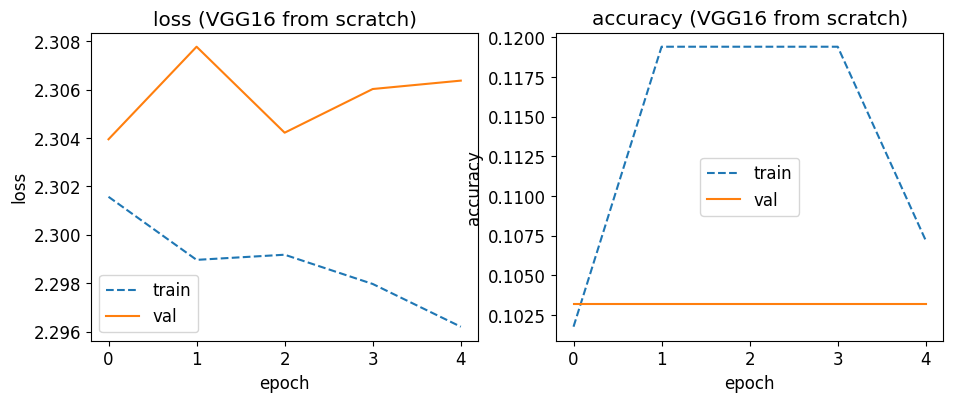

VGG16 from scratch -> test top-1: 11.6%, top-3: 30.2%  (random guessing: 10% top-1)


In [ ]:
plot_history(history_scratch, "(VGG16 from scratch)")
_, test_topk = evaluate(scratch_model, test_ds)
print(f"VGG16 from scratch -> test top-1: {100 * test_topk[1]:.1f}%, top-3: {100 * test_topk[3]:.1f}%  (random guessing: 10% top-1)")

**The model is not doing well** (typically close to random guessing or only slightly better).

Why? We are asking ~15 million randomly initialized convolution parameters to learn useful features from only a few hundred images — and a deep plain network with no normalization is also hard to optimize. Possible fixes:
- collect many more images per class (slow and expensive), or
- **reuse what a network already learned on a huge dataset → Transfer learning.**

# ☕ Break (5 minutes)

Let's first recall why deep learning took off:
- bigger and better datasets such as ImageNet,
- faster and cheaper GPUs,
- better algorithms (architectures, optimizers, training procedures), and
- **pretrained models** that took weeks to train but can be reused in minutes.

The last point, **transfer learning**, is the underappreciated hero: it lets us adapt an existing model to our task in minutes.

Before we discuss the process of transfer learning, let's quickly take a step back and review the primary reasons for the boom in deep learning:

- Availability of bigger and better-quality datasets like ImageNet
- Better compute available; i.e., faster and cheaper GPUs
- Better algorithms (model architecture, optimizer, and training procedure)
- Availability of pretrained models that have taken weeks to train but can be quickly reused
- The last point is probably one of the biggest reasons for the widespread adoption of deep learning by the masses.
  -  If every training task took weeks, not more than a handful of researchers with deep pockets would be working in this area.
  - Thanks to transfer learning, the underappreciated hero of training models, we can now adapt an existing model to suit our task in as little as a few minutes

For example-


 <center>  <img src='https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/249/217/original/6.png?1793084674'>
   <caption><center> <font color='yellow'> Figure: <font color='yellow'>  : Transfer learning in real time <br>  </center></caption>

## What is Transfer Learning?

A model trained for one task is reused as the **starting point** for a second, related task.

- Early layers of a CNN learn **generic** features (edges, colours, textures); later layers become more **task-specific**. So we keep the generic layers and replace the task-specific ones.
- Typical recipe: remove the final fully-connected layers, add a new head for our classes, then train.

<img src='https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/249/218/original/7.png?1793084693'>

**Two strategies**

| | Feature extraction | Fine-tuning |
|---|---|---|
| Pretrained backbone | **frozen** (not updated) | **some or all layers unfrozen**, trained with a small learning rate |
| Trained part | only the new head | new head + part of the backbone |
| Best when | very little data, task similar to ImageNet | more data and/or a task that differs from ImageNet |
| Risk | may underfit if tasks differ a lot | overfitting; a high learning rate can destroy pretrained features |

With only a few dozen images per class we start with **feature extraction**. Benefits: much less training time and, usually, **much higher accuracy** than training from scratch on a small dataset.

> **🤖 AI Infusion #2 (optional):** ask an AI assistant when you would choose fine-tuning over feature extraction, and what can go wrong if you fine-tune with too high a learning rate or too little data.

## Transfer learning with VGG16, step by step

**Step 1 — load VGG16 pretrained on ImageNet** and look at its original head:

In [ ]:
model_tl = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
print(model_tl.classifier)     # original head: 25088 -> 4096 -> 4096 -> 1000 ImageNet classes

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:05<00:00, 105MB/s]


Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=1000, bias=True)
)


**Step 2 — freeze everything.** Setting `requires_grad = False` tells autograd not to compute gradients for these parameters, so the optimizer never changes them.

In [ ]:
for param in model_tl.parameters():
    param.requires_grad = False

#### **Quiz-5**
In PyTorch, how do you freeze a layer so it isn't updated during training?

> (a) `layer.freeze()`  (b) `layer.trainable = False`  (c) `for p in layer.parameters(): p.requires_grad = True`  (d) `for p in layer.parameters(): p.requires_grad = False`

**Ans: (d).** `requires_grad = False` stops autograd from computing/accumulating gradients for those parameters.

**Step 3 — replace the head.** We swap the 1000-class classifier for a single new `Linear` layer with 10 outputs. Newly created layers have `requires_grad=True` by default, so **only this layer will be trained**.

In [ ]:
model_tl.classifier = nn.Sequential(nn.Linear(512 * 7 * 7, 10))   # new, trainable head for our 10 landmarks
model_tl = model_tl.to(device)
count_params(model_tl)

Total params: 14,965,578 | Trainable params: 250,890


Only ~250 thousand parameters (25,088 × 10 weights + 10 biases) are trainable, out of ~15 million (the convolutional backbone has 14.7M frozen parameters; the 120M-parameter original FC layers were removed).

**Step 4 — train.** The optimizer only receives the trainable parameters.

In [ ]:
optimizer = optim.Adam([p for p in model_tl.parameters() if p.requires_grad], lr=1e-3)
history_tl = fit(model_tl, train_ds, val_ds, optimizer, epochs=5)

Epoch 1/5 - loss: 0.7987 - acc: 0.7639 - val_loss: 0.4416 - val_acc: 0.8774
Epoch 2/5 - loss: 0.0444 - acc: 0.9864 - val_loss: 0.6147 - val_acc: 0.8645
Epoch 3/5 - loss: 0.0046 - acc: 0.9986 - val_loss: 0.3948 - val_acc: 0.9355
Epoch 4/5 - loss: 0.0005 - acc: 1.0000 - val_loss: 0.3527 - val_acc: 0.9355
Epoch 5/5 - loss: 0.0003 - acc: 1.0000 - val_loss: 0.3548 - val_acc: 0.9355


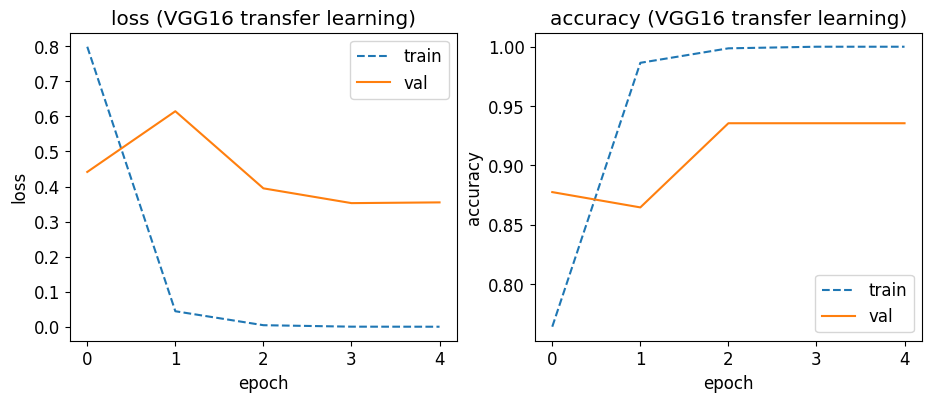

In [ ]:
plot_history(history_tl, "(VGG16 transfer learning)")

**Step 5 — evaluate on the test set** and compare with the model trained from scratch:

In [ ]:
_, tl_topk = evaluate(model_tl, test_ds)
print(f"VGG16 transfer learning -> test top-1: {100 * tl_topk[1]:.1f}%, top-3: {100 * tl_topk[3]:.1f}%")
print(f"VGG16 from scratch      -> test top-1: {100 * test_topk[1]:.1f}%, top-3: {100 * test_topk[3]:.1f}%")

VGG16 transfer learning -> test top-1: 97.7%, top-3: 100.0%
VGG16 from scratch      -> test top-1: 11.6%, top-3: 30.2%


Using the pretrained convolutional layers we typically reach a **much higher accuracy** with far less training than the model trained from scratch (exact numbers vary from run to run, and with a test set this small each image is worth about 2 points).

**Step 6 — look at the predictions.** We show 15 random test images with the predicted class and confidence (blue = correct, red = wrong). Since the images are normalized, we first *undo* the normalization for display.

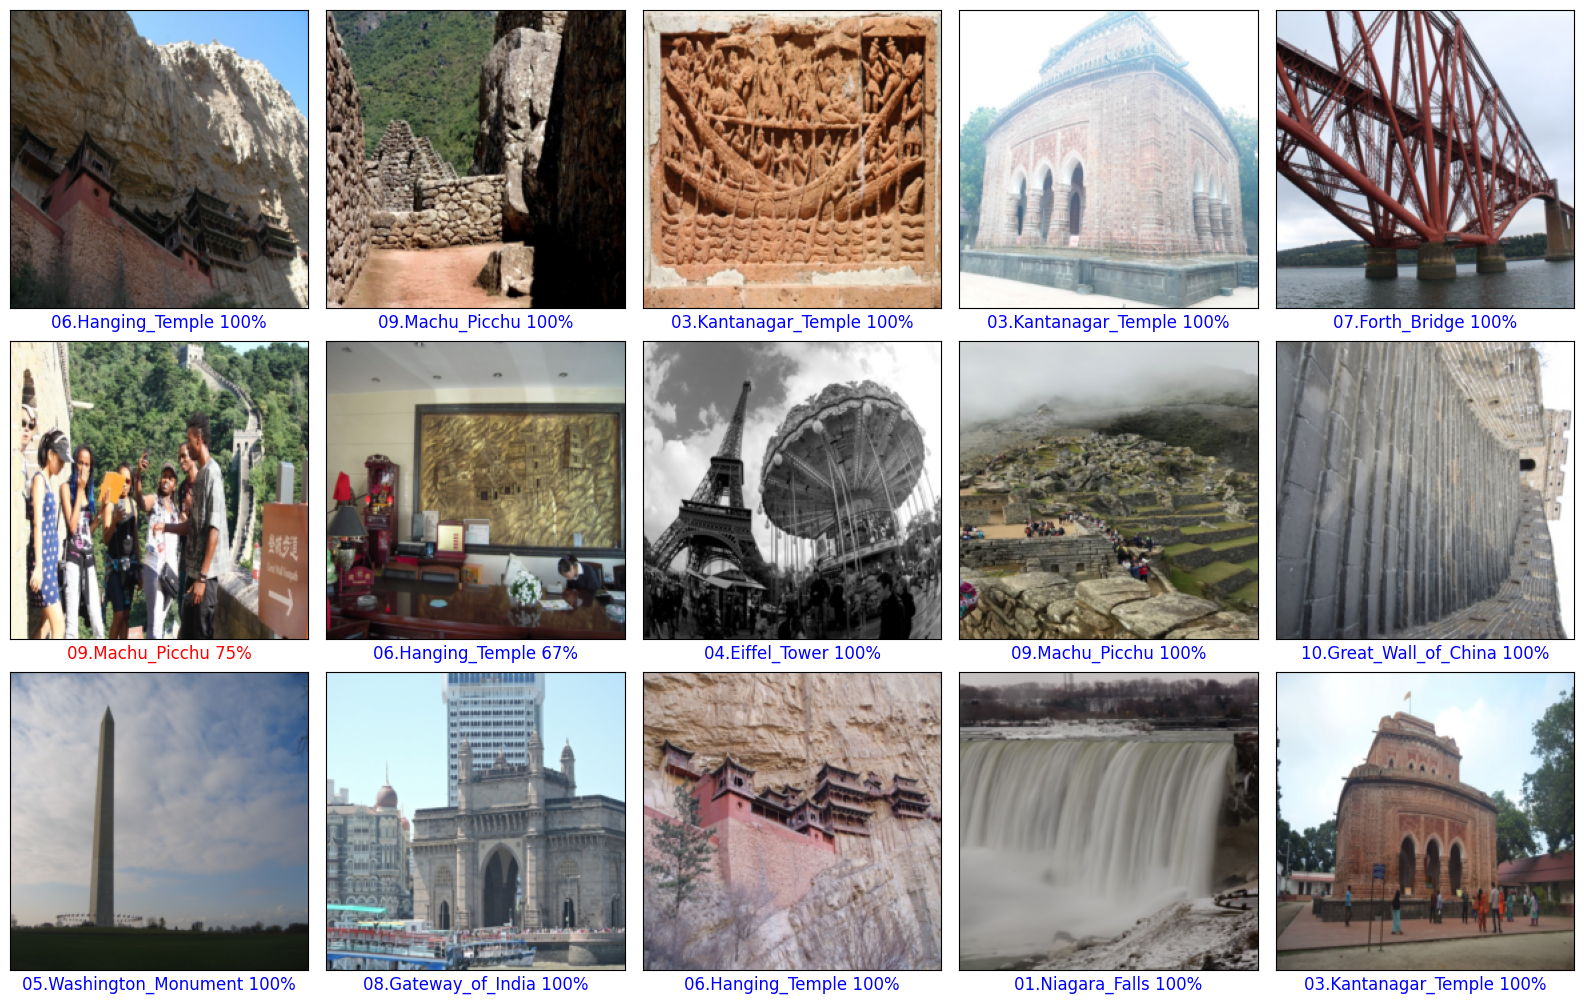

In [ ]:
def denormalize(img):                       # (C,H,W) normalized -> displayable image in [0,1]
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (img.cpu() * std + mean).clamp(0, 1)

@torch.no_grad()
def show_predictions(model, dataset, n=15, cols=5):
    model.eval()
    idxs = random.sample(range(len(dataset)), min(n, len(dataset)))
    rows = (len(idxs) + cols - 1) // cols
    plt.figure(figsize=(3.2 * cols, 3.4 * rows))
    for i, idx in enumerate(idxs):
        img, label = dataset[idx]
        probs = torch.softmax(model(img[None].to(device)), dim=1)[0].cpu()
        pred = probs.argmax().item()
        plt.subplot(rows, cols, i + 1)
        plt.imshow(denormalize(img).permute(1, 2, 0)); plt.xticks([]); plt.yticks([])
        plt.xlabel(f"{dataset.classes[pred]} {100 * probs[pred]:.0f}%", color="blue" if pred == label else "red")
    plt.tight_layout(); plt.show()

show_predictions(model_tl, test_dataset)

### **What are the shortcomings of VGGNet?**
- If we look at the number of parameters, it has **~138-144M parameters!**, which takes approximately 500 MB to store!
- This is a **major drawback of this network**
- The majority of parameters come from the last 3 FC layers (roughly 120 million of them in the full configuration)
- The convolutional part only has around 15-20 million weights
- Conv layers are more important than FC layers, as they capture features from the image
- **How can we overcome this shortcoming?**
 - We can reduce the parameters in the last FC layers by using Global Average Pooling (GAP) when going from conv layers to FC layers. This helps reduce the number of parameters.

 - It is a pooling layer applied over the *entire* feature map, using the average instead of the maximum.
 - The feature map just before VGG's FC layers has the dimension 7 x 7 x 512
 - Every 7x7 feature map is averaged down to a single value
 - So 7x7x512 -> GAP -> 1x1x512 (which can feed straight into a dense layer)
 - With GAP, we can get rid of most of the FC-layer parameters, and it **gives good performance** in practice

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/046/614/original/Screenshot_2023-09-06_at_11.33.09_AM.png?1693980201 width=800>

- This gives rise to the next architecture: **GoogLeNet (Inception)**, which uses global average pooling at the end (and later **ResNet**, which solves the optimization problem of deep networks with skip connections).

#### **Quiz-6**

What is the total number of parameters in the 1st FC layer (7×7×512 → 4096) of VGGNet?

> (a) (7 * 7 * 512 + 1) * 4096  (b) 7 * 7 * 512 * 4096  (c) 4096  (d) None of the above

**Ans: (a)** = (25,088 + 1) × 4,096 ≈ **102.8 million** parameters. This single layer is the bottleneck of VGGNet.

### Conclusion

Accuracy of the pretrained models in `torchvision` on ImageNet (single-crop), from the [torchvision documentation](https://docs.pytorch.org/vision/stable/models.html):

| Model | Parameters | Top-1 acc (%) | Top-5 acc (%) |
|---|---|---|---|
| AlexNet | 61.1M | 56.5 | 79.1 |
| VGG16 | 138.4M | 71.6 | 90.4 |
| VGG19 | 143.7M | 72.4 | 90.9 |

*(The 2012 AlexNet competition result of ~84.7% top-5 came from an ensemble of several CNNs, which is why it is higher than the single model here.)*

- Training a deep CNN such as VGG from scratch on a small dataset performs poorly.
- **Transfer learning** with a pretrained VGG16 (frozen convolutional layers + a new head) trains in minutes and performs far better.

## Fine-tuning the last conv block

Feature extraction keeps the entire backbone frozen. **Fine-tuning** additionally unfreezes the *last* convolutional block (the most task-specific one) and trains it with a **much smaller learning rate** than the new head, so we adjust the pretrained features gently instead of destroying them.

In [ ]:
model_ft = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
for param in model_ft.parameters():
    param.requires_grad = False
model_ft.classifier = nn.Sequential(nn.Linear(512 * 7 * 7, 10))      # new head (trainable)
for param in model_ft.features[24:].parameters():                    # last conv block (conv5_1 ... pool5)
    param.requires_grad = True
model_ft = model_ft.to(device)
count_params(model_ft)

optimizer = optim.Adam([
    {"params": model_ft.features[24:].parameters(), "lr": 1e-5},     # tiny LR for pretrained layers
    {"params": model_ft.classifier.parameters(),    "lr": 1e-3},     # larger LR for the new head
])
history_ft = fit(model_ft, train_ds, val_ds, optimizer, epochs=3)
_, ft_topk = evaluate(model_ft, test_ds)
print(f"Fine-tuned -> test top-1: {100 * ft_topk[1]:.1f}%, top-3: {100 * ft_topk[3]:.1f}%")

Total params: 14,965,578 | Trainable params: 7,330,314
Epoch 1/3 - loss: 0.8625 - acc: 0.7368 - val_loss: 0.2945 - val_acc: 0.9355
Epoch 2/3 - loss: 0.0613 - acc: 0.9851 - val_loss: 0.3495 - val_acc: 0.9032
Epoch 3/3 - loss: 0.0094 - acc: 0.9959 - val_loss: 0.3110 - val_acc: 0.9161
Fine-tuned -> test top-1: 95.3%, top-3: 100.0%


> **🤖 AI Infusion #3 (optional, needs an API key):** you can ask an LLM to hypothesize why your model confuses certain landmark pairs. Collect the most common (true, predicted) mistakes from the test set, put them in a prompt, and send it with the `anthropic` SDK (`client.messages.create(model="claude-sonnet-5-5", ...)`). Always treat the answer as a hypothesis to verify by looking at the images.

### Exercises
1. Does training the VGG model (with transfer learning) for more epochs improve performance? Watch the validation curve.
2. Does adding more FC layers (e.g. `Linear(25088, 256) → ReLU → Dropout → Linear(256, 10)`) improve accuracy?
3. Replace the flatten + `Linear(25088, 10)` head by **Global Average Pooling** (`nn.AdaptiveAvgPool2d(1)` → `Linear(512, 10)`). How many trainable parameters do you save, and what happens to accuracy?
4. Add data augmentation (random flips/crops) to the training transform. Is it useful when the backbone is frozen?